# Feature Extraction and Price Prediction for Mobile Phones

**Goal:** Find which phone features affect the price the most and build a model that predicts the price of a mobile phone.

**Steps in this notebook**
1. Data exploration
2. Data preprocessing (missing values, outliers, inconsistencies, encoding)
3. Visual analysis
4. Feature extraction (correlation + mutual information)
5. Model building and evaluation
6. Feature importance analysis
7. Recommendations and problems faced

## 1. Import libraries

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GroupKFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Data exploration
First we load the data and look at its structure, data types and value ranges.

In [2]:
# The Excel file must be in the same folder as this notebook
df = pd.read_excel("Project_4_data_pdf.xlsx")
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (541, 12)


,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    str    
 2   Colour         541 non-null    str    
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    str    
 7   Front Camera   541 non-null    str    
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    str    
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 50.8 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,541.0,289.711645,182.359185,0.0,135.00,273.00,434.00,642.00
Memory,541.0,110.550832,60.600694,16.0,64.00,128.00,128.00,256.00
RAM,541.0,5.397412,1.984923,2.0,4.00,6.00,8.00,8.00
Battery_,541.0,4871.587800,780.148862,800.0,5000.00,5000.00,5000.00,7000.00
AI Lens,541.0,0.062847,0.242911,0.0,0.00,0.00,0.00,1.00
Mobile Height,541.0,16.431201,2.523553,4.5,16.51,16.71,16.94,41.94
Prize,541.0,16228.375231,10793.588322,920.0,9290.00,13499.00,19280.00,80999.00


**What we notice**
- The dataset has 541 rows and 12 columns, and there are **no missing values**.
- `Rear Camera` and `Front Camera` are stored as text (e.g. `50MP`), so they must be converted to numbers.
- Column names are messy: `Unnamed: 0` (just an index), `Battery_`, `Processor_`, and `Prize` (a spelling mistake for Price).
- `Mobile Height` has a maximum of 41.94 cm, which is not possible for a phone.

In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Exact duplicate rows (ignoring the index column):", df.drop(columns="Unnamed: 0").duplicated().sum())
print()
print("Unique values -> Model:", df["Model"].nunique(),
      "| Colour:", df["Colour"].nunique(),
      "| Processor_:", df["Processor_"].nunique())
print()
print("Rear Camera values:", sorted(df["Rear Camera"].unique()))

Missing values per column:
Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64

Exact duplicate rows (ignoring the index column): 10

Unique values -> Model: 187 | Colour: 275 | Processor_: 123

Rear Camera values: ['0MP', '108MP', '12MP', '13MP', '16MP', '200MP', '2MP', '32MP', '40MP', '48MP', '50MP', '5MP', '64MP', '8MP']


There are **10 duplicate rows**, and `Model`, `Colour` and `Processor_` have too many unique values (187, 275 and 123). Let us look at the suspicious values in more detail.

In [6]:
# Look closely at the suspicious values found above
print("1) Mobile Height above 20 cm (a phone cannot be 41.94 cm tall):")
print(df[df["Mobile Height"] > 20][["Model", "Mobile Height"]])
print()
print("2) Very cheap 'feature phones' (battery <= 2000 mAh) with impossible RAM/Memory:")
print(df[df["Battery_"] <= 2000][["Model", "Memory", "RAM", "Battery_", "Prize"]].head(8))
print()
print("3) Same iPhone 14 Plus listed with different RAM values:")
print(df[df["Model"] == "APPLE iPhone 14 Plus"][["Model", "RAM", "Prize"]])
print()
print("4) Messy Processor names (same chip written in many ways):")
print(df["Processor_"].value_counts().head(12))

1) Mobile Height above 20 cm (a phone cannot be 41.94 cm tall):
              Model  Mobile Height
75  MOTOROLA G62 5G          41.94
88  MOTOROLA G62 5G          41.94

2) Very cheap 'feature phones' (battery <= 2000 mAh) with impossible RAM/Memory:
              Model  Memory  RAM  Battery_  Prize
98   Micromax IN 2C     128    6       800   1449
108      micromax 2     128    8      1900   1849
116        micromax     128    4      1000   1422
118      micromax 1     256    8       800   1299
133      Micromax 3     128    4      1020   2615
152      micromax 3      64    4       800   2490
155      micromax 2     256    8       800   1299
156      micromax 3     256    4      1020   2499

3) Same iPhone 14 Plus listed with different RAM values:
                    Model  RAM  Prize
493  APPLE iPhone 14 Plus    6  80999
520  APPLE iPhone 14 Plus    3  80999
525  APPLE iPhone 14 Plus    4  80999

4) Messy Processor names (same chip written in many ways):
Processor_
Qualcomm Snapdrago

## 3. Data preprocessing
Problems found and what we do about each one:

| Problem | Solution |
|---|---|
| Useless index column `Unnamed: 0`, messy column names | Drop and rename |
| 10 duplicate rows | Remove |
| Cameras stored as text (`50MP`) | Convert to numbers |
| Height of 41.94 cm (outlier / typing error) | Replace with the median height |
| 14 basic feature phones with impossible RAM/Memory (e.g. 256 GB on a Rs. 1,299 phone) | Keep them but add a `FeaturePhone` flag |
| 5G information hidden in the model name | Extract a new `Is5G` column |
| `Model` has 187 unique names | Extract `Brand` |
| `Processor_` has 123 messy names | Group into chip family (Qualcomm, MediaTek, ...) |
| `Colour` has 275 unique names | Group into base colours |

In [7]:
# Step 1: drop the useless index column, rename messy column names, remove duplicates
df = df.drop(columns="Unnamed: 0")
df = df.rename(columns={
    "Battery_": "Battery",
    "Processor_": "Processor",
    "Prize": "Price",
    "Mobile Height": "Height",
    "Rear Camera": "RearCam",
    "Front Camera": "FrontCam",
    "AI Lens": "AILens",
})

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", before - len(df), "| Rows left:", len(df))

# Step 2: camera columns are text like "50MP" -> convert to numbers
df["RearCam"] = df["RearCam"].str.replace("MP", "").astype(int)
df["FrontCam"] = df["FrontCam"].str.replace("MP", "").astype(int)
df[["RearCam", "FrontCam"]].describe().T

Duplicates removed: 10 | Rows left: 531


,count,mean,std,min,25%,50%,75%,max
RearCam,531.0,46.227872,31.392146,0.0,13.0,50.0,50.0,200.0
FrontCam,531.0,12.045198,9.105142,0.0,5.0,8.0,16.0,60.0


In [8]:
# Step 3: fix the height outlier (41.94 cm is a data-entry error)
# Real phone heights are between 4.5 and 17.5 cm, so we replace the wrong values with the median height.
median_height = df.loc[df["Height"] <= 20, "Height"].median()
df.loc[df["Height"] > 20, "Height"] = median_height
print("Max height now:", df["Height"].max())

# Step 4: flag basic feature phones (tiny battery). Their RAM/Memory values are unreliable,
# so instead of deleting them we give the model a flag that says "this is a feature phone".
df["FeaturePhone"] = (df["Battery"] <= 2000).astype(int)
print("Feature phones:", df["FeaturePhone"].sum())

# Step 5: 5G information is hidden inside the Model name, so we extract it
df["Is5G"] = df["Model"].str.contains("5G", case=False).astype(int)
print("5G phones:", df["Is5G"].sum())

Max height now: 17.65
Feature phones: 14
5G phones: 189


In [9]:
# Step 6: Model has 187 unique names -> one-hot encoding would create 187 columns for only ~530 rows.
# Instead we extract the BRAND (first word of the model name), which is much more useful.
df["Brand"] = df["Model"].str.split().str[0].str.lower()
df["Brand"] = df["Brand"].replace({"micromax1": "micromax"})   # spelling mistake in the data

# Brands with fewer than 5 phones are grouped into "other"
brand_counts = df["Brand"].value_counts()
df["Brand"] = df["Brand"].where(df["Brand"].map(brand_counts) >= 5, "other")
df["Brand"].value_counts()

Brand
realme      97
redmi       74
infinix     65
vivo        60
poco        58
samsung     53
motorola    45
oppo        16
tecno       16
micromax    14
other       14
google       9
oneplus      5
apple        5
Name: count, dtype: int64

In [10]:
# Step 7: Processor has 123 messy names (e.g. "Helio G35", "Mediatek Helio G35", "MediaTek Helio G35").
# We group them into the chip company / family.
def chip_family(processor, brand):
    p = str(processor).lower()
    if brand == "apple" or p == "ios":
        return "Apple"
    if "tensor" in p:
        return "Google"
    if any(word in p for word in ["snapdragon", "qualcomm", "sm6", "sm7", "sm8"]):
        return "Qualcomm"
    if any(word in p for word in ["mediatek", "helio", "dimensity", "mtk", "mt6", "mt8"]) or re.fullmatch(r"g\d\d", p):
        return "MediaTek"
    if any(word in p for word in ["exynos", "s5e", "sec "]):
        return "Exynos"
    if any(word in p for word in ["unisoc", "spreadtrum", "tiger", "sc9", "sc6", "t6", "t7"]):
        return "Unisoc"
    return "Other"

df["Chip"] = [chip_family(p, b) for p, b in zip(df["Processor"], df["Brand"])]
df["Chip"].value_counts()

Chip
MediaTek    280
Qualcomm    129
Unisoc       69
Exynos       28
Other        12
Google        8
Apple         5
Name: count, dtype: int64

In [11]:
# Step 8: Colour has 275 unique names (e.g. "Midnight Black", "Force Black", "Carbon Black").
# We group them into simple base colours.
def colour_group(colour):
    c = str(colour).lower()
    base_colours = {"black": "Black", "blue": "Blue", "green": "Green", "white": "White",
                    "silver": "Silver", "gray": "Gray", "grey": "Gray", "gold": "Gold",
                    "purple": "Purple", "yellow": "Yellow", "orange": "Orange", "red": "Red"}
    for word, group in base_colours.items():
        if word in c:
            return group
    return "Other"

df["ColourGroup"] = df["Colour"].apply(colour_group)
print(df["ColourGroup"].value_counts())
print()
print("Cleaned data shape:", df.shape)
df[["Model", "Brand", "Chip", "ColourGroup", "Memory", "RAM", "Battery", "RearCam", "FrontCam", "Price"]].head()

ColourGroup
Black     133
Blue      128
Other      88
Green      54
White      27
Gray       22
Gold       21
Silver     16
Purple     15
Yellow     12
Orange     10
Red         5
Name: count, dtype: int64

Cleaned data shape: (531, 16)


,Model,Brand,Chip,ColourGroup,Memory,RAM,Battery,RearCam,FrontCam,Price
0,Infinix SMART 7,infinix,Unisoc,Black,64,4,6000,13,5,7299
1,Infinix SMART 7,infinix,Unisoc,Blue,64,4,6000,13,5,7299
2,MOTOROLA G32,motorola,Qualcomm,Gray,128,8,5000,50,16,11999
3,POCO C50,poco,MediaTek,Blue,32,2,5000,8,5,5649
4,Infinix HOT 30i,infinix,MediaTek,Gold,128,8,5000,50,5,8999


## 4. Visual analysis

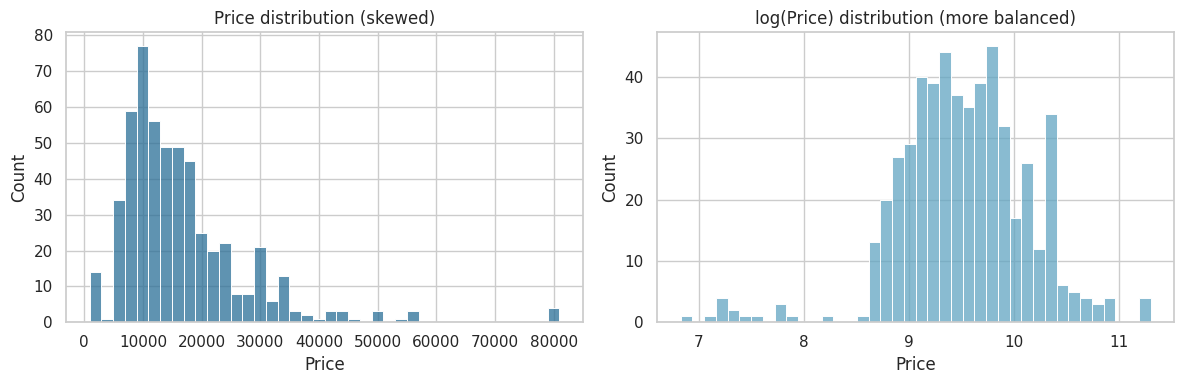

In [12]:
# Price distribution: most phones are cheap, a few premium phones are very expensive (right-skewed)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price"], bins=40, ax=axes[0], color="#2a6f97")
axes[0].set_title("Price distribution (skewed)")
sns.histplot(np.log1p(df["Price"]), bins=40, ax=axes[1], color="#61a5c2")
axes[1].set_title("log(Price) distribution (more balanced)")
plt.tight_layout()
plt.show()

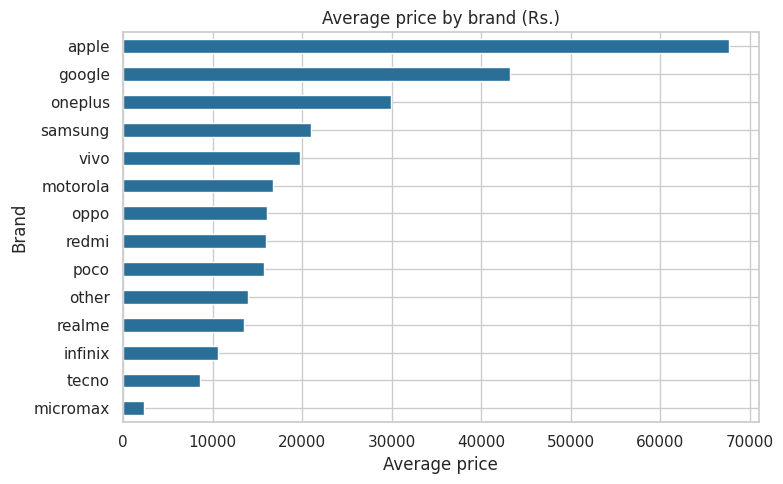

In [13]:
# Average price by brand
brand_price = df.groupby("Brand")["Price"].mean().sort_values()
brand_price.plot(kind="barh", figsize=(8, 5), color="#2a6f97")
plt.title("Average price by brand (Rs.)")
plt.xlabel("Average price")
plt.tight_layout()
plt.show()

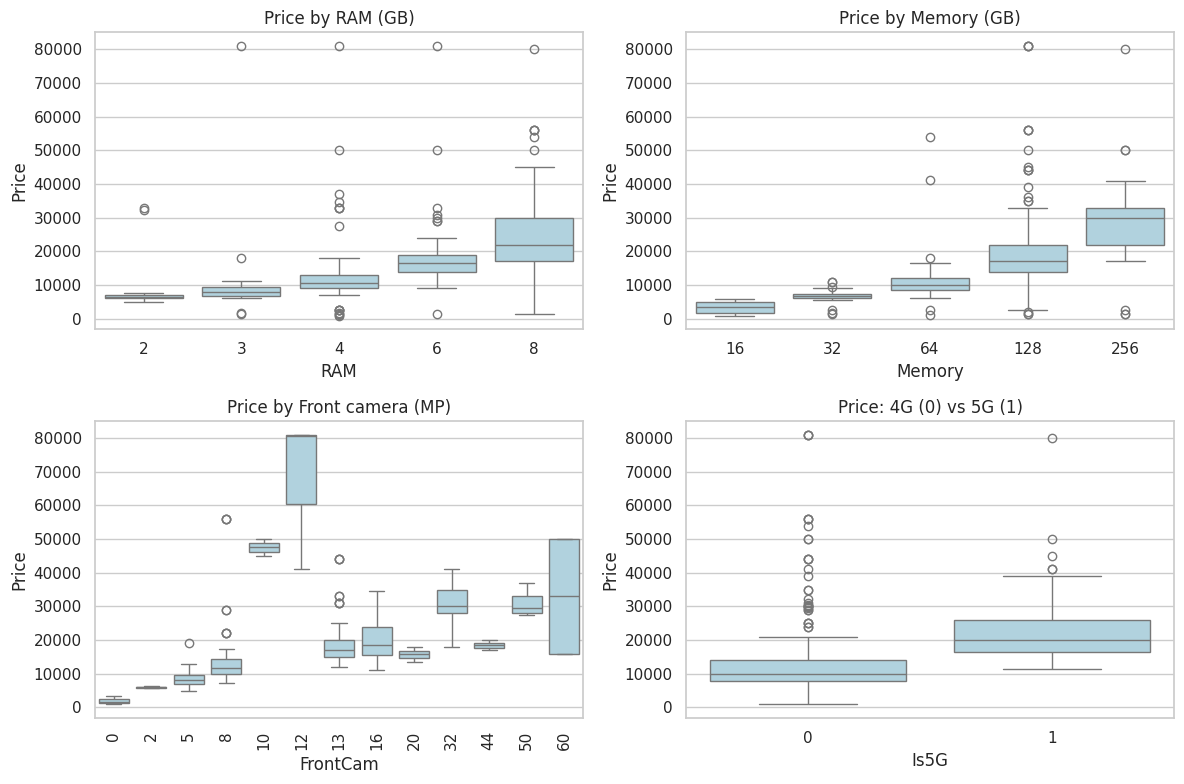

In [14]:
# Price vs RAM, Memory, Front camera and 5G
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.boxplot(x="RAM", y="Price", data=df, ax=axes[0, 0], color="#a9d6e5")
axes[0, 0].set_title("Price by RAM (GB)")
sns.boxplot(x="Memory", y="Price", data=df, ax=axes[0, 1], color="#a9d6e5")
axes[0, 1].set_title("Price by Memory (GB)")
sns.boxplot(x="FrontCam", y="Price", data=df, ax=axes[1, 0], color="#a9d6e5")
axes[1, 0].set_title("Price by Front camera (MP)")
axes[1, 0].tick_params(axis="x", rotation=90)
sns.boxplot(x="Is5G", y="Price", data=df, ax=axes[1, 1], color="#a9d6e5")
axes[1, 1].set_title("Price: 4G (0) vs 5G (1)")
plt.tight_layout()
plt.show()

**Insights**
- Price is right-skewed: most phones are cheap, a few premium phones (Apple, Google) cost Rs. 45,000 to 81,000. Using `log(Price)` makes the data more balanced, so the models will learn on log price.
- Apple (about Rs. 67,600) and Google (about Rs. 43,200) are far more expensive than the other brands. Micromax and Tecno are the cheapest.
- Price rises steadily with RAM, Memory and front camera resolution.
- 5G phones cost more on average (about Rs. 22,100) than non-5G phones (about Rs. 13,100).

## 5. Encoding categorical variables
Machine learning models need numbers, so we use **one-hot encoding** for `Brand`, `Chip` and `ColourGroup`.
We do not one-hot encode `Model` directly because 187 new columns for about 530 rows would make the model confusing; `Brand` carries the useful part of it.

In [15]:
# One-hot encoding: turn the text columns (Brand, Chip, ColourGroup) into 0/1 columns.
# We drop Model, Colour and Processor because we already extracted Brand, ColourGroup and Chip from them.
X = pd.get_dummies(df.drop(columns=["Model", "Colour", "Processor", "Price"]),
                   columns=["Brand", "Chip", "ColourGroup"], dtype=int)
y = df["Price"]

print("Final feature matrix:", X.shape)
X.head()

Final feature matrix: (531, 42)


,Memory,RAM,Battery,RearCam,FrontCam,AILens,Height,FeaturePhone,Is5G,Brand_apple,Brand_google,Brand_infinix,Brand_micromax,Brand_motorola,Brand_oneplus,...,Chip_Other,Chip_Qualcomm,Chip_Unisoc,ColourGroup_Black,ColourGroup_Blue,ColourGroup_Gold,ColourGroup_Gray,ColourGroup_Green,ColourGroup_Orange,ColourGroup_Other,ColourGroup_Purple,ColourGroup_Red,ColourGroup_Silver,ColourGroup_White,ColourGroup_Yellow
0,64,4,6000,13,5,1,16.76,0,0,0,0,1,0,0,0,...,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0
1,64,4,6000,13,5,1,16.76,0,0,0,0,1,0,0,0,...,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0
2,128,8,5000,50,16,0,16.64,0,0,0,0,0,0,1,0,...,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0
3,32,2,5000,8,5,0,16.56,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4,128,8,5000,50,5,1,16.76,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


## 6. Feature extraction
We rank the features using two different methods:
- **Correlation:** how strongly each feature moves together with price (linear relationship).
- **Mutual information:** how much each feature tells us about price (also catches non-linear relationships).

Memory           0.564
RAM              0.529
FrontCam         0.529
Brand_apple      0.462
Chip_Apple       0.462
RearCam          0.407
Is5G             0.398
Brand_google     0.326
Chip_Google      0.325
Chip_Unisoc     -0.316
Chip_Qualcomm    0.234
FeaturePhone    -0.219
dtype: float64


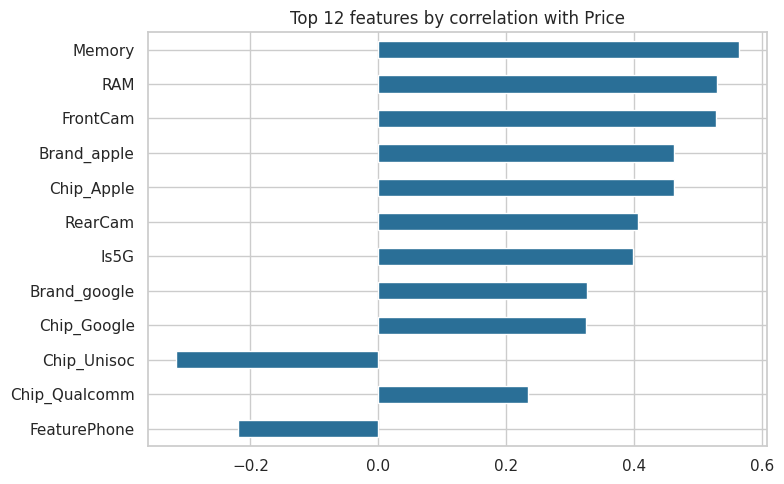

In [16]:
# Feature extraction method 1: correlation of every feature with Price
corr = X.corrwith(y).sort_values(key=abs, ascending=False)
print(corr.head(12).round(3))

corr.head(12)[::-1].plot(kind="barh", figsize=(8, 5), color="#2a6f97")
plt.title("Top 12 features by correlation with Price")
plt.tight_layout()
plt.show()

FrontCam         0.785
RAM              0.682
Memory           0.681
RearCam          0.675
Height           0.633
Battery          0.399
Is5G             0.323
Chip_Unisoc      0.154
Chip_Qualcomm    0.150
Chip_MediaTek    0.126
FeaturePhone     0.125
Brand_infinix    0.103
dtype: float64


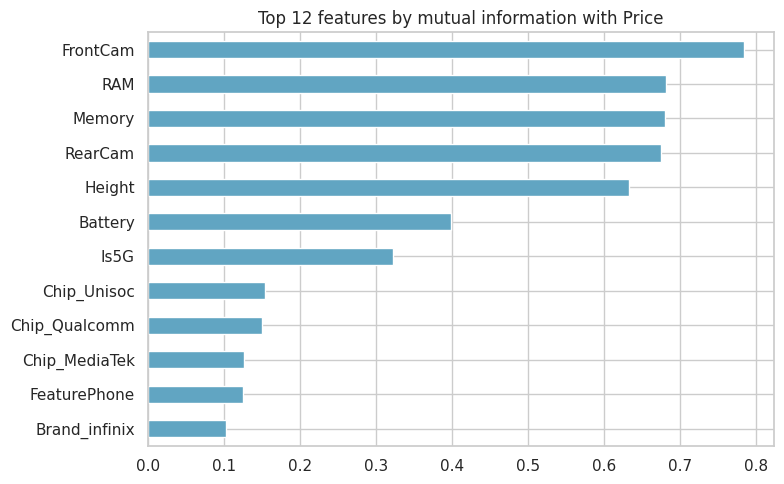

In [17]:
# Feature extraction method 2: mutual information (also catches non-linear relationships)
mi = mutual_info_regression(X, y, random_state=42)
mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False)
print(mi_scores.head(12).round(3))

mi_scores.head(12)[::-1].plot(kind="barh", figsize=(8, 5), color="#61a5c2")
plt.title("Top 12 features by mutual information with Price")
plt.tight_layout()
plt.show()

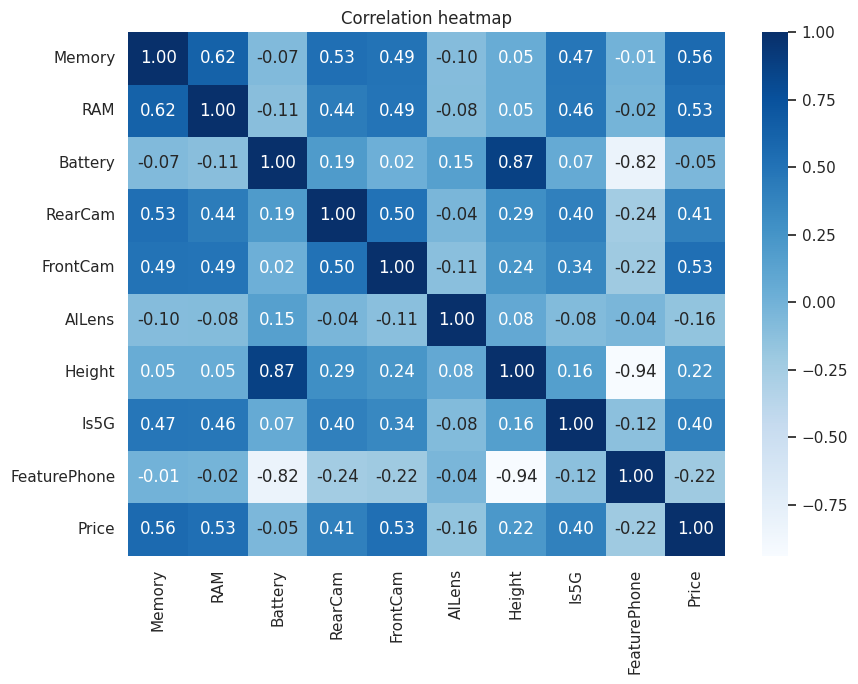

In [18]:
# Correlation heatmap of the main numeric features
numeric_cols = ["Memory", "RAM", "Battery", "RearCam", "FrontCam", "AILens", "Height", "Is5G", "FeaturePhone", "Price"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

**Result of feature extraction**
- Both methods agree that **Front camera, RAM, Memory and Rear camera** are the strongest features. Premium brands (Apple, Google), 5G, and a Unisoc chip (cheap phones) also show a clear relationship with price.
- **Colour** shows almost no relationship with price. The only exception is the "Other" colour group, which holds fancy marketing names (e.g. Starlight, Lemongrass) that appear mostly on premium phones. **AI Lens** is also weak, and it is mostly found on cheaper phones.
- RAM, Memory, Front camera and Rear camera are correlated with each other (0.44 to 0.62), so they partly carry the same information.

## 7. Model building
We split the data into 80% training and 20% testing, then compare four models.

In [19]:
# Split into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", X_train.shape[0], "| Testing rows:", X_test.shape[0])

Training rows: 424 | Testing rows: 107


In [20]:
# Prices are skewed, so every model learns on log(Price) and converts back to Rs. automatically.
def make_model(regressor):
    return TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)

models = {
    "Linear Regression": make_model(LinearRegression()),
    "Decision Tree": make_model(DecisionTreeRegressor(max_depth=8, random_state=42)),
    "Random Forest": make_model(RandomForestRegressor(n_estimators=300, random_state=42)),
    "Gradient Boosting": make_model(GradientBoostingRegressor(random_state=42)),
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "MAE (Rs.)": mean_absolute_error(y_test, pred),
        "RMSE (Rs.)": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results).sort_values("MAE (Rs.)").reset_index(drop=True)
results_df.round(3)

,Model,MAE (Rs.),RMSE (Rs.),R2
0,Gradient Boosting,1834.856,4507.296,0.807
1,Random Forest,1920.137,4519.134,0.806
2,Decision Tree,2219.823,5421.838,0.721
3,Linear Regression,3042.663,6553.658,0.593


**Evaluation metrics**
- **MAE** = average error in rupees.
- **RMSE** = like MAE but punishes big mistakes more.
- **R2** = how much of the price variation the model explains (1 is perfect).

**Gradient Boosting** gives the best result (lowest MAE and RMSE, highest R2). Linear Regression is the weakest because the relationship between features and price is not a straight line.

Best model: Gradient Boosting


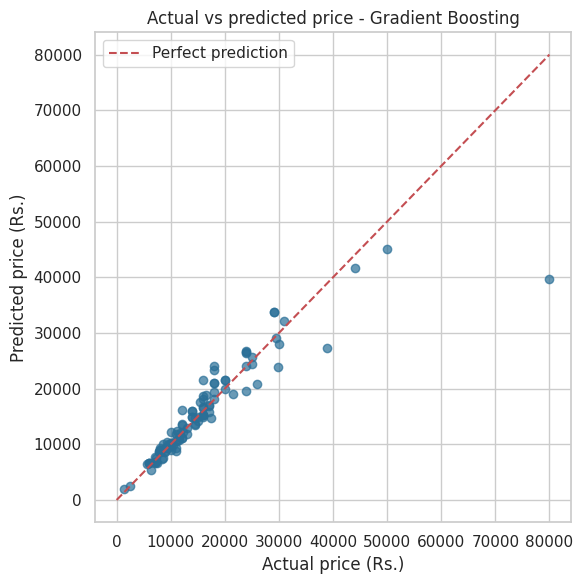

In [21]:
# Best model = lowest error. Plot actual vs predicted prices on the unseen test data.
best_name = results_df.loc[0, "Model"]
best_model = models[best_name]
best_pred = predictions[best_name]
print("Best model:", best_name)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.7, color="#2a6f97")
limit = [0, max(y_test.max(), best_pred.max())]
plt.plot(limit, limit, "r--", label="Perfect prediction")
plt.xlabel("Actual price (Rs.)")
plt.ylabel("Predicted price (Rs.)")
plt.title("Actual vs predicted price - " + best_name)
plt.legend()
plt.tight_layout()
plt.show()

### Extra check: testing on phone models the model has never seen

In [22]:
# Honest check: the same phone model appears many times (different colours) with almost the same row.
# With a random split, a colour variant in the test set can have its twin in the training set (data leakage).
# Here we keep ALL rows of a phone model together (GroupKFold), so the model is tested on phones it has never seen.
group_pred = cross_val_predict(
    make_model(GradientBoostingRegressor(random_state=42)),
    X, y, cv=GroupKFold(n_splits=5), groups=df["Model"]
)
print("Gradient Boosting on completely unseen phone models:")
print("MAE  (Rs.):", round(mean_absolute_error(y, group_pred)))
print("RMSE (Rs.):", round(np.sqrt(mean_squared_error(y, group_pred))))
print("R2        :", round(r2_score(y, group_pred), 3))

Gradient Boosting on completely unseen phone models:
MAE  (Rs.): 2931
RMSE (Rs.): 6146
R2        : 0.678


The score is lower than on the random split (R2 0.68 against 0.81, MAE about Rs. 2,900 against Rs. 1,800). This is expected, because the dataset contains many colour variants of the same phone and a random split lets the model see a "twin" of a test phone while training. The honest accuracy for a **brand new phone model** is therefore around R2 0.68.

## 8. Feature importance analysis
Now we confirm the features found in the feature-extraction step using the trained model.

FrontCam         0.560
Memory           0.088
Battery          0.085
RearCam          0.070
Height           0.043
Is5G             0.038
FeaturePhone     0.037
RAM              0.018
Brand_google     0.012
Brand_apple      0.010
Brand_infinix    0.007
Brand_samsung    0.005
dtype: float64


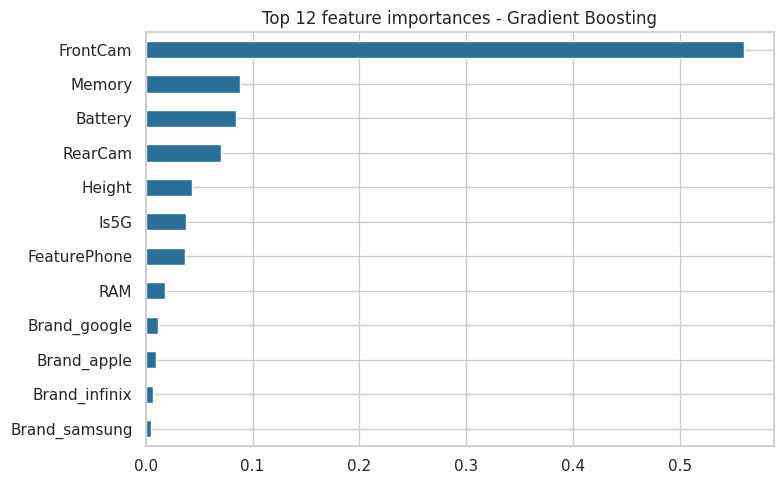

In [23]:
# Feature importance from the model itself
importance = pd.Series(best_model.regressor_.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance.head(12).round(3))

importance.head(12)[::-1].plot(kind="barh", figsize=(8, 5), color="#2a6f97")
plt.title("Top 12 feature importances - " + best_name)
plt.tight_layout()
plt.show()

FrontCam             0.312
Battery              0.199
Brand_samsung        0.062
Memory               0.052
Brand_infinix        0.045
RearCam              0.043
RAM                  0.030
Is5G                 0.027
Brand_google         0.024
Height               0.017
ColourGroup_Other    0.010
Brand_poco           0.006
dtype: float64


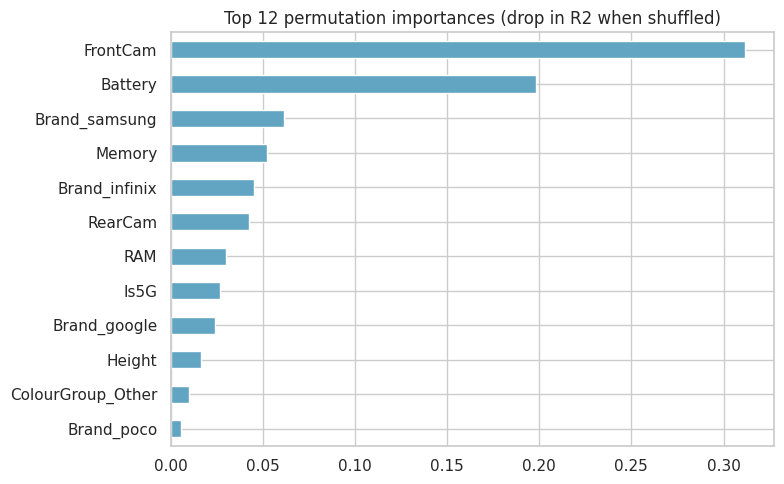

In [24]:
# Permutation importance (more reliable): shuffle one feature on the TEST data and see how much the score drops
perm = permutation_importance(best_model, X_test, y_test, n_repeats=20, random_state=42)
perm_scores = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
print(perm_scores.head(12).round(3))

perm_scores.head(12)[::-1].plot(kind="barh", figsize=(8, 5), color="#61a5c2")
plt.title("Top 12 permutation importances (drop in R2 when shuffled)")
plt.tight_layout()
plt.show()

FrontCam        0.560
Memory          0.088
Battery         0.085
RearCam         0.070
Brand           0.045
Height          0.043
Is5G            0.038
FeaturePhone    0.037
RAM             0.018
Chip            0.012
ColourGroup     0.002
AILens          0.000
dtype: float64


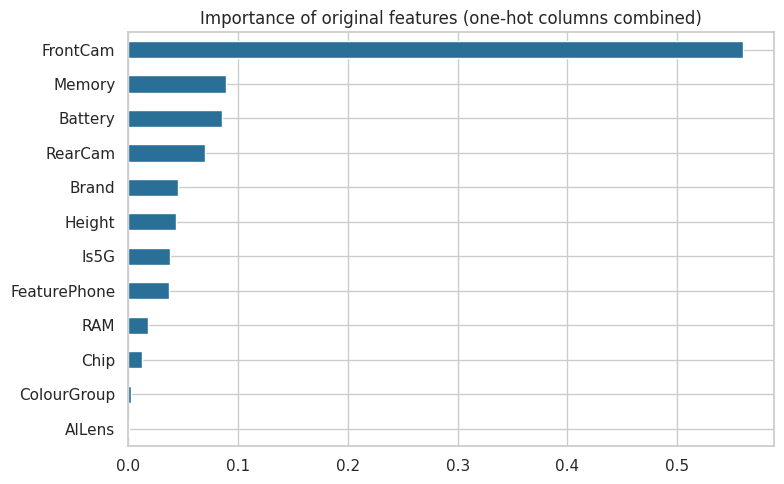

In [25]:
# One-hot columns split one feature into many (e.g. Brand_apple, Brand_vivo...).
# Add them back together to see the importance of the ORIGINAL feature.
def original_feature(column):
    for prefix in ["Brand_", "Chip_", "ColourGroup_"]:
        if column.startswith(prefix):
            return prefix[:-1]
    return column

grouped = importance.groupby(original_feature).sum().sort_values(ascending=False)
print(grouped.round(3))

grouped[::-1].plot(kind="barh", figsize=(8, 5), color="#2a6f97")
plt.title("Importance of original features (one-hot columns combined)")
plt.tight_layout()
plt.show()

**Findings**
- **Front camera resolution is the most important feature by far** (about 56% of the model's importance, and the biggest drop in score in the permutation test). It works like a "phone class" signal: budget phones have 5 to 8 MP, mid-range 13 to 16 MP, and premium phones 32 MP and above.
- **Memory, Battery, Rear camera, Brand, Height, 5G and RAM** come next. 
- RAM looks less important here than in the correlation step because it is strongly related to Memory and the cameras, so the model shares the credit between them.
- Battery matters to the model, but not as "bigger battery = higher price" (its correlation with price is about -0.05). Premium phones such as iPhones and Pixels have smaller batteries, so battery helps the model to separate phone segments.
- **Colour (0.3%) and AI Lens (0.04%) are almost useless** for predicting the price, which matches the feature-extraction step.

## 9. Recommendations
1. **Price on the main spec bundle: front camera, storage, RAM and rear camera.** They explain most of the price. For example, the average price is about Rs. 8,500 for 5 MP front camera phones, Rs. 20,000 for 13 to 16 MP, and Rs. 31,000 for 32 MP and above.
2. **Storage and RAM tiers are clear price steps:** the average price is about Rs. 10,600 for 64 GB, Rs. 19,700 for 128 GB and Rs. 28,000 for 256 GB; and about Rs. 11,900 for 4 GB RAM, Rs. 17,500 for 6 GB and Rs. 24,200 for 8 GB. These tiers can be used to design price bands.
3. **5G justifies a premium:** 5G phones are on average about Rs. 9,000 more expensive. Offering 5G in the mid-range is a good way to move a product up one price band.
4. **Brand is a pricing power by itself:** Apple, Google, OnePlus and Samsung sell at higher prices than similar-spec phones from budget brands, so brand value should be considered in pricing.
5. **Do not charge extra for colour or "AI Lens":** neither has a real effect on price. Colour options can be decided only by customer demand, and AI Lens should not be used to justify a higher price.
6. **Use the model as a guide, not as a final price.** It predicts within about Rs. 1,800 on average for known phone types and about Rs. 2,900 for new phone models, so a final price should still be reviewed by the pricing team.

## 10. Problems faced during the project
| # | Problem | How it was solved |
|---|---|---|
| 1 | The dataset link in the project statement is a Google Sheet, which had to be downloaded as a file | Downloaded as Excel and loaded with `pd.read_excel` |
| 2 | Messy column names (`Unnamed: 0`, `Battery_`, `Processor_`, `Prize`) | Dropped / renamed |
| 3 | Cameras stored as text (`50MP`) | Removed "MP" and converted to numbers |
| 4 | 10 duplicate rows | Removed |
| 5 | Height outlier of 41.94 cm (2 rows) | Replaced with the median height |
| 6 | Feature phones with impossible RAM / Memory (e.g. 256 GB, 8 GB RAM at Rs. 1,299) | Kept, and added a `FeaturePhone` flag |
| 7 | iPhone RAM is inconsistent (same iPhone 14 Plus shown with 3, 4 and 6 GB) | Only 5 Apple rows, so left as it is and mentioned as a limitation |
| 8 | 123 processor names, 275 colour names, 187 model names | Grouped into chip family, base colour and brand |
| 9 | Corrupted text in some values (e.g. colour `M3)`, processor names with strange characters) | Handled by keyword matching, the rest went to "Other" |
| 10 | Price is highly skewed (Rs. 920 to Rs. 80,999) | Trained models on log(Price) which improved Linear Regression and Gradient Boosting |
| 11 | Same phone appears many times in different colours, so a random split gives a too-optimistic score | Added a GroupKFold test on unseen phone models (R2 0.68) |
| 12 | Very few premium phones (5 Apple, 9 Google) | Model is less reliable for premium phones; listed as a limitation |

## 11. Limitations and future work
- The dataset is small (531 rows after cleaning), and premium phones are rare.
- Front camera importance is partly a "phone segment" signal and not purely a cause of the price.
- Future work: tune hyper-parameters, add features such as screen type, refresh rate and launch year, and collect more premium phones.